# Análisis de Conglomerados: una tipología de las entidades federativas

Cuaderno del **Capítulo 5** de las notas. Primero reproduce los ejemplos a mano con cinco entidades; después segmenta las 32 entidades con sus puntuaciones factoriales (F1: nivel socioeconómico, F2: envejecimiento) calculadas en el cuaderno del Capítulo 3.

**Contenido**
1. Ejemplo a mano: matriz de distancias y enlaces
2. k-medias: dos arranques, dos óptimos locales
3. Elección del número de grupos: codo, silueta, Calinski–Harabasz, gap y BIC
4. La tipología con k = 4 y su perfil
5. Validación: Ward, estabilidad bootstrap y correlación cofenética

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
import itertools
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, adjusted_rand_score

## 1. Ejemplo a mano: cinco entidades

In [2]:
nombres = ["NL", "QR", "VER", "OAX", "CHIS"]
P5 = np.array([[1.1, -0.6], [0.7, -2.2], [-0.8, 1.7], [-1.7, 1.0], [-2.5, -0.7]])
pd.DataFrame(squareform(pdist(P5)), index=nombres, columns=nombres).round(2)

,NL,QR,VER,OAX,CHIS
NL,0.00,1.65,2.98,3.22,3.60
QR,1.65,0.00,4.18,4.00,3.53
VER,2.98,4.18,0.00,1.14,2.94
OAX,3.22,4.00,1.14,0.00,1.88
CHIS,3.60,3.53,2.94,1.88,0.00


In [3]:
# Cada fila de linkage: [grupo i, grupo j, altura, tamaño]. En Ward, altura = sqrt(2·Δ).
for metodo in ["single", "complete", "ward"]:
    print(metodo, "\n", linkage(P5, metodo).round(2))

single 
 [[2.   3.   1.14 2.  ]
 [0.   1.   1.65 2.  ]
 [4.   5.   1.88 3.  ]
 [6.   7.   2.98 5.  ]]
complete 
 [[2.   3.   1.14 2.  ]
 [0.   1.   1.65 2.  ]
 [4.   5.   2.94 3.  ]
 [6.   7.   4.18 5.  ]]
ward 
 [[2.   3.   1.14 2.  ]
 [0.   1.   1.65 2.  ]
 [4.   5.   2.77 3.  ]
 [6.   7.   5.11 5.  ]]


## 2. k-medias: dos arranques, dos óptimos locales

In [4]:
def lloyd(P, centros):
    while True:
        lab = ((P[:, None, :] - centros[None]) ** 2).sum(2).argmin(1)
        nuevos = np.array([P[lab == j].mean(0) for j in range(len(centros))])
        if np.allclose(nuevos, centros):
            return lab, ((P - centros[lab]) ** 2).sum()
        centros = nuevos

for arranque in [[0, 1], [2, 3]]:
    lab, J = lloyd(P5, P5[arranque].copy())
    print(f"Arranque en {[nombres[i] for i in arranque]}: grupos = {lab}, J = {J:.2f}")

# Óptimo global: enumerar las 15 particiones en dos grupos
def W(Y, lab):
    return sum(((Y[lab == c] - Y[lab == c].mean(0)) ** 2).sum() for c in np.unique(lab))
mejores = sorted((W(P5, np.isin(range(5), S).astype(int)), [nombres[i] for i in S])
                 for r in (1, 2) for S in itertools.combinations(range(5), r))
print("Óptimo global:", mejores[0][1], "contra el resto, W =", round(mejores[0][0], 2))

Arranque en ['NL', 'QR']: grupos = [0 1 0 0 1], J = 13.11
Arranque en ['VER', 'OAX']: grupos = [0 1 0 1 1], J = 15.12
Óptimo global: ['NL', 'QR'] contra el resto, W = 5.85


## 3. Elección del número de grupos (32 entidades)

In [5]:
F = pd.read_csv("../../03 Factor Analysis/04 Entidades ENIGH/enigh2024_puntuaciones.csv", index_col=0)
Y = F.values
n = len(Y)

def gap(Y, kmax=7, B=500, semilla=2026):
    rng = np.random.default_rng(semilla)
    Yc = Y - Y.mean(0)
    _, _, Vt = np.linalg.svd(Yc, full_matrices=False)
    Yp = Yc @ Vt.T
    lo, hi = Yp.min(0), Yp.max(0)
    g, s = [], []
    for k in range(1, kmax + 1):
        lab = np.zeros(len(Y), int) if k == 1 else KMeans(k, n_init=20, random_state=0).fit(Y).labels_
        ref = []
        for b in range(B):
            Yr = rng.uniform(lo, hi, Y.shape) @ Vt
            lr = np.zeros(len(Y), int) if k == 1 else KMeans(k, n_init=5, random_state=b).fit(Yr).labels_
            ref.append(np.log(W(Yr, lr)))
        g.append(np.mean(ref) - np.log(W(Y, lab)))
        s.append(np.std(ref) * np.sqrt(1 + 1 / B))
    return np.array(g), np.array(s)

filas = []
for k in range(1, 8):
    lab = np.zeros(n, int) if k == 1 else KMeans(k, n_init=50, random_state=0).fit(Y).labels_
    filas.append({"k": k, "W": W(Y, lab),
                  "silueta": np.nan if k == 1 else silhouette_score(Y, lab),
                  "CH": np.nan if k == 1 else calinski_harabasz_score(Y, lab),
                  "BIC": GaussianMixture(k, covariance_type="spherical", n_init=20, random_state=0).fit(Y).bic(Y)})
crit = pd.DataFrame(filas).set_index("k")
crit["gap"], crit["s_gap"] = gap(Y)
crit.round(3)

,W,silueta,CH,BIC,gap,s_gap
k,,,,,,
1,60.171,NaN,NaN,188.073,0.643,0.120
2,39.648,0.322,15.529,165.938,0.431,0.130
3,25.175,0.351,20.156,173.318,0.366,0.139
4,16.903,0.358,23.892,158.094,0.340,0.142
5,12.674,0.366,25.297,165.254,0.304,0.127
6,9.801,0.365,26.723,166.985,0.315,0.148
7,7.106,0.397,31.114,168.374,0.387,0.142


El estadístico gap es máximo en k = 1 (no hay grupos naturales) y el BIC prefiere k = 4. Las siluetas (0.32–0.40) indican una estructura débil: la segmentación es una *disección* útil de un continuo.

## 4. La tipología con k = 4

In [6]:
km = KMeans(4, n_init=100, random_state=0).fit(Y)
orden = np.argsort(-km.cluster_centers_[:, 0])
lab = np.array([{o: i + 1 for i, o in enumerate(orden)}[l] for l in km.labels_])
NOMBRES = {1: "G1 Ciudad de México", 2: "G2 Norte y polos de empleo",
           3: "G3 Intermedio envejecido", 4: "G4 Sur y centro con rezago"}
for gpo in range(1, 5):
    print(NOMBRES[gpo], "→", F.index[lab == gpo].tolist())

X = pd.read_csv("../../03 Factor Analysis/04 Entidades ENIGH/enigh2024_entidades.csv", index_col=0)
perfil = X.assign(grupo=lab).groupby("grupo").mean()
perfil["n"] = np.bincount(lab)[1:]
perfil.round(3)

G1 Ciudad de México → ['Ciudad de México']
G2 Norte y polos de empleo → ['Aguascalientes', 'Baja California', 'Baja California Sur', 'Coahuila', 'Chihuahua', 'Jalisco', 'Nuevo León', 'Querétaro', 'Quintana Roo', 'Sonora', 'Tabasco']
G3 Intermedio envejecido → ['Colima', 'Hidalgo', 'México', 'Morelos', 'Nayarit', 'San Luis Potosí', 'Sinaloa', 'Tamaulipas', 'Veracruz', 'Yucatán']
G4 Sur y centro con rezago → ['Campeche', 'Chiapas', 'Durango', 'Guanajuato', 'Guerrero', 'Michoacán', 'Oaxaca', 'Puebla', 'Tlaxcala', 'Zacatecas']


,ing_pc,edu_jefe,menores_sh,perceptores,mayores65_sh,trab_sh,n
grupo,,,,,,,
1,10.781,7.434,0.107,0.796,0.144,0.610,1
2,10.436,6.641,0.174,0.655,0.084,0.682,11
3,10.186,6.171,0.165,0.674,0.111,0.637,10
4,9.918,5.693,0.195,0.633,0.100,0.652,10


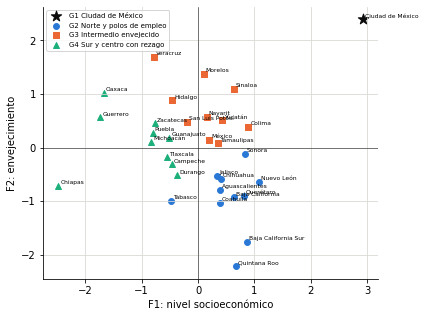

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
estilos = {1: (TINTA, "*", 120), 2: (AZUL, "o", 35), 3: (NARANJA, "s", 35), 4: (VERDE, "^", 35)}
for gpo, (col, mk, s) in estilos.items():
    m = lab == gpo
    ax.scatter(Y[m, 0], Y[m, 1], color=col, marker=mk, s=s, label=NOMBRES[gpo])
for i, e in enumerate(F.index):
    ax.annotate(e, (Y[i, 0], Y[i, 1]), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax.axhline(0, color=TINTA, lw=0.5); ax.axvline(0, color=TINTA, lw=0.5)
ax.set_xlabel("F1: nivel socioeconómico"); ax.set_ylabel("F2: envejecimiento"); ax.legend(fontsize=7)
plt.show()

## 5. Validación

Silueta promedio: 0.358 {1: 0.0, 2: 0.469, 3: 0.345, 4: 0.286}
ARI k-medias contra Ward: 0.638
Correlación cofenética (single): 0.802
Correlación cofenética (complete): 0.704
Correlación cofenética (average): 0.817
Correlación cofenética (ward): 0.486


ARI bootstrap: media 0.59 | percentil 5 0.292


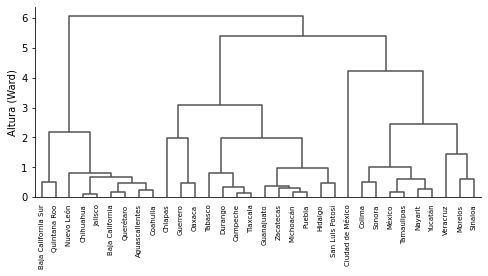

In [8]:
sil = silhouette_samples(Y, lab)
print("Silueta promedio:", sil.mean().round(3), {g_: sil[lab == g_].mean().round(3) for g_ in range(1, 5)})
Zw = linkage(Y, "ward")
print("ARI k-medias contra Ward:", round(adjusted_rand_score(lab, fcluster(Zw, 4, "maxclust")), 3))
for m in ["single", "complete", "average", "ward"]:
    print(f"Correlación cofenética ({m}):", round(cophenet(linkage(Y, m), pdist(Y))[0], 3))
rng = np.random.default_rng(2026)
aris = []
for b in range(500):
    idx = rng.choice(n, n, replace=True)
    u = np.unique(idx)
    aris.append(adjusted_rand_score(lab[u], KMeans(4, n_init=10, random_state=b).fit(Y[idx]).predict(Y[u])))
print("ARI bootstrap: media", np.mean(aris).round(3), "| percentil 5", np.percentile(aris, 5).round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
dendrogram(Zw, labels=F.index.tolist(), leaf_rotation=90, leaf_font_size=7, color_threshold=0,
           above_threshold_color="#52514e", ax=ax)
ax.grid(False); ax.set_ylabel("Altura (Ward)"); plt.show()

## Ejercicios para el alumno

1. Repita la aplicación sin la Ciudad de México. ¿Cambian el número de grupos sugerido y los grupos?
2. Agrupe con los seis indicadores estandarizados en lugar de las puntuaciones factoriales y compare con el ARI.
3. Con `../03 Clustering Customer/marketing_campaign.csv` (variables métricas y categóricas), segmente clientes con k-medoides y la distancia de Gower.